## Assignment 4

Andrew Irwin


You are free to use any code developed in the class or the textbook.

When your solution contains computer code, please submit the work as a Jupyter notebook. Write your name near the top of the notebook - where it says "YOUR NAME" above. Write any free-form text responses in "markdown" blocks, not code blocks with comment characters.

If your solution contains hand-written calculations, it is probably easiest to submit these on paper in class. You can type mathematics using LaTeX expressions between dollar signs (if you know how to do that), but hand-written is usually easier and is fine.

All question numbers refer to exercises in the textbook.

## Q 5.1.3

The following two vectors define a flying saucer shape.
   

In [1]:
xs = [ 0,0.51,0.96,1.06,1.29,1.55,1.73,2.13,2.61,
      2.19,1.76,1.56,1.25,1.04,0.58,0 ]
ys = [ 0,0.16,0.16,0.43,0.62,0.48,0.19,0.18,0,
      -0.12,-0.12,-0.29,-0.30,-0.15,-0.16,0 ];

We can regard both $x$ and $y$ as functions of a parameter $t$, with the points being values given at 
$s = 0, \dots, 15$.

(a) Use `Spline1D` or `cubic_spline_interpolation` once on each coordinate as functions of $t$, 
and make a picture of the flying saucer.

(b) One drawback of the result in part (a) is the noticeable corner at the left side, which corresponds to $t=0$ from above and $t=15$ from below. There is a periodic variation on cubic spline interpolation that you can invoke by adding the keyword `periodic=true` to the `Spline1D` call. Use this to re-plot the flying saucer.


In [1]:
using Interpolations # for cubic_spline_interpolation
using Dierckx # for Spline1D
using Plots
using DataFrames
using ForwardDiff
using LinearAlgebra
using DifferentialEquations
using Printf
using SpecialFunctions
using LaTeXStrings

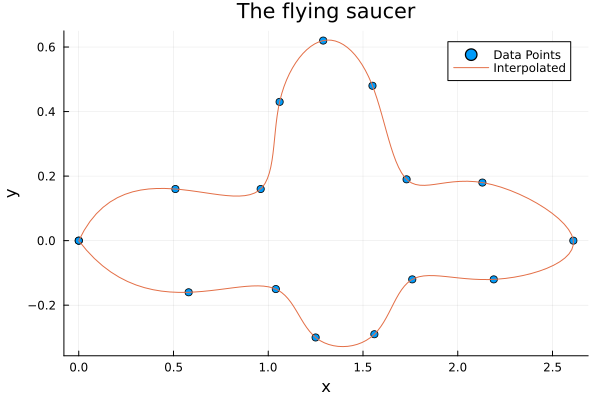

In [4]:
# (a)
ts = 1:length(xs)
xt = Spline1D(ts, xs)
yt = Spline1D(ts, ys)

scatter(xs, ys, label="Data Points", xlabel="x", ylabel="y", title="The flying saucer")
plot!(t -> xt(t), t -> yt(t), 1, length(xs), label="Interpolated")

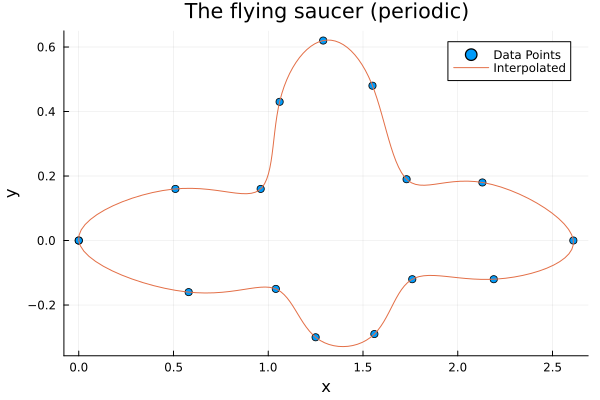

In [5]:
# (b)
ts = 1:length(xs)
xt = Spline1D(ts, xs, periodic=true)
yt = Spline1D(ts, ys, periodic=true)

scatter(xs, ys, label="Data Points", xlabel="x", ylabel="y", title="The flying saucer (periodic)")
plot!(t -> xt(t), t -> yt(t), 1, length(xs), label="Interpolated")

## Q 5.4.3

Let $f(x) = e^{-x}$, $x = 0.5$, and $h=0.2$. Using Function 5.4.7 to get the necessary weights on five nodes centered at $x$, find finite-difference approximations to the first, second, third, and fourth derivatives of $f$. Make a table showing the exact derivatives, finite-difference approximate values and the errors in each case.


In [6]:
function fdweights(t,m)
# This is a compact implementation, not an efficient one.
    # Recursion for one weight. 
    function weight(t,m,r,k)
        # Inputs
        #   t: vector of nodes 
        #   m: order of derivative sought 
        #   r: number of nodes to use from t 
        #   k: index of node whose weight is found

        if (m<0) || (m>r)        # undefined coeffs must be zero
            c = 0
        elseif (m==0) && (r==0)  # base case of one-point interpolation
            c = 1
        else                     # generic recursion
            if k<r
                c = (t[r+1]*weight(t,m,r-1,k) -
                    m*weight(t,m-1,r-1,k))/(t[r+1]-t[k+1])
            else
                numer = r > 1 ? prod(t[r]-x for x in t[1:r-1]) : 1
                denom = r > 0 ? prod(t[r+1]-x for x in t[1:r]) : 1
                β = numer/denom
                c = β*(m*weight(t,m-1,r-1,r-1) - t[r]*weight(t,m,r-1,r-1))
            end
        end
        return c
    end
    r = length(t)-1
    w = zeros(size(t))
    return [ weight(t,m,r,k) for k=0:r ]
end

fdweights (generic function with 1 method)

In [7]:
f = x -> exp(-x)
h = 0.2
x = 0.5

ds = [0., 0., 0., 0.]
real_ds = [0., 0., 0., 0.]
error = [0., 0., 0., 0.]
for n = 1:4
    m = (n + 1) ÷ 2
    ws = fdweights(-m:m, n) # central difference
    fs = zeros(1, length(ws))
    m = length(ws) ÷ 2
    for i = -m:m
        fs[i + m + 1] = f(x + i * h)
    end
    ds[n] = sum(fs.*ws') / (h ^ n)
    real_ds[n] = (-1) ^ n * exp(-x)
    error[n] = abs(ds[n] - real_ds[n])
end

In [8]:
@show DataFrame(; real_ds, ds, error);

DataFrame(; real_ds, ds, error) = 4×3 DataFrame
 Row │ real_ds    ds         error
     │ Float64    Float64    Float64
─────┼──────────────────────────────────
   1 │ -0.606531  -0.610582  0.00405163
   2 │  0.606531   0.608555  0.00202447
   3 │ -0.606531  -0.61262   0.00608962
   4 │  0.606531   0.610586  0.00405569


## Q 5.4.3 Automatic differentiation version

Compute the 1, 2, 3, and 4th derivatives of $f(x) = \exp(x)$ evaluated at $x = 0.5$ using the `ForwardDiff` package and automatic differentiation. Make a version of the table from the previous question.

In [10]:
f1(x) = exp(x)
x = 0.5

ds = [0., 0., 0., 0.]
real_ds = [0., 0., 0., 0.]
error = [0., 0., 0., 0.]
for n = 1:4
    m = (n + 1) ÷ 2
    ws = fdweights(-m:m, n) # central difference
    fs = zeros(1, length(ws))
    m = length(ws) ÷ 2
    for i = -m:m
        fs[i + m + 1] = f(x + i * h)
    end
    ds[n] = sum(fs.*ws') / (h ^ n)
    real_ds[n] = exp(x)
    error[n] = abs(ds[n] - real_ds[n])
end

fds = [0., 0., 0., 0.]
fds[1] = ForwardDiff.derivative(f1, x::Real)
fds[2] = ForwardDiff.derivative(y -> ForwardDiff.derivative(f1, y), x::Real)
fds[3] = ForwardDiff.derivative(x -> ForwardDiff.derivative(x -> ForwardDiff.derivative(f1, x), x), x::Real)
fds[4] = ForwardDiff.derivative(x -> ForwardDiff.derivative(x -> ForwardDiff.derivative(x -> ForwardDiff.derivative(f1, x), x), x), x::Real)
error_f = abs.(fds .- real_ds)

@show DataFrame(; real_ds, ds, error, fds, error_f);

DataFrame(; real_ds, ds, error, fds, error_f) = 4×5 DataFrame
 Row │ real_ds  ds         error    fds      error_f
     │ Float64  Float64    Float64  Float64  Float64
─────┼───────────────────────────────────────────────
   1 │ 1.64872  -0.610582  2.2593   1.64872      0.0
   2 │ 1.64872   0.608555  1.04017  1.64872      0.0
   3 │ 1.64872  -0.61262   2.26134  1.64872      0.0
   4 │ 1.64872   0.610586  1.03813  1.64872      0.0


In [11]:
f2(x) = exp(-x)
x = 0.5

ds = [0., 0., 0., 0.]
real_ds = [0., 0., 0., 0.]
error = [0., 0., 0., 0.]
for n = 1:4
    m = (n + 1) ÷ 2
    ws = fdweights(-m:m, n) # central difference
    fs = zeros(1, length(ws))
    m = length(ws) ÷ 2
    for i = -m:m
        fs[i + m + 1] = f(x + i * h)
    end
    ds[n] = sum(fs.*ws') / (h ^ n)
    real_ds[n] = (-1) ^ n * exp(-x)
    error[n] = abs(ds[n] - real_ds[n])
end

fds = [0., 0., 0., 0.]
fds[1] = ForwardDiff.derivative(f2, x::Real)
fds[2] = ForwardDiff.derivative(y -> ForwardDiff.derivative(f2, y), x::Real)
fds[3] = ForwardDiff.derivative(x -> ForwardDiff.derivative(x -> ForwardDiff.derivative(f2, x), x), x::Real)
fds[4] = ForwardDiff.derivative(x -> ForwardDiff.derivative(x -> ForwardDiff.derivative(x -> ForwardDiff.derivative(f2, x), x), x), x::Real)
error_f = abs.(fds .- real_ds)

@show DataFrame(; real_ds, ds, error, fds, error_f);

DataFrame(; real_ds, ds, error, fds, error_f) = 4×5 DataFrame
 Row │ real_ds    ds         error       fds        error_f
     │ Float64    Float64    Float64     Float64    Float64
─────┼──────────────────────────────────────────────────────
   1 │ -0.606531  -0.610582  0.00405163  -0.606531      0.0
   2 │  0.606531   0.608555  0.00202447   0.606531      0.0
   3 │ -0.606531  -0.61262   0.00608962  -0.606531      0.0
   4 │  0.606531   0.610586  0.00405569   0.606531      0.0


## Q 5.6.1 part d

Estimate the integral $\int_0^1\sqrt{x}\log(x)\ dx$ (exact value is $-4/9$) using the Trapezoid rule and $n = 10\cdot 2^k$ nodes for $k = 1, \dots, 10$. Make a log-log plot of the errors and determine if the method is second-order accurate. 

Hint: use `eps()` as your lower limit of integration.

In [12]:
function trapezoid(f,a,b,n)
    h = (b-a)/n
    t = range(a,b,length=n+1)
    y = f.(t)
    T = h * ( sum(y[2:n]) + 0.5*(y[1] + y[n+1]) )
    return T,t,y
end

trapezoid (generic function with 1 method)

In [13]:
f3 = x -> sqrt(x) * log(x)

exact = - 4/9
m = 10

ns = Vector{Int64}(undef, m)
errs = zeros(m)
for k = 1:m
    ns[k] = 10 * 2 ^ k
    low = eps()
    T, ts, ys = trapezoid(f3, low, 1, ns[k]);
    errs[k] = abs(T + 4 / 9)
end

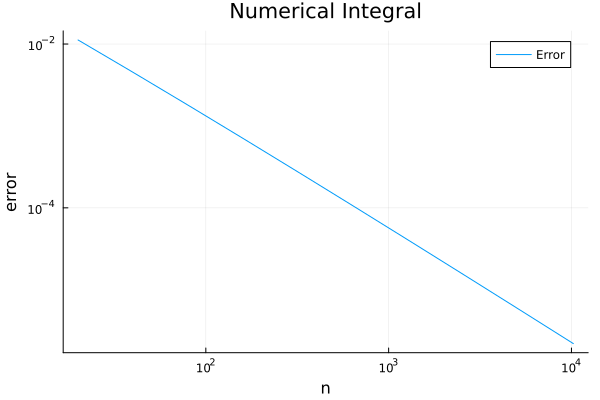

In [14]:
plot(ns, errs, yaxis=:log, xaxis=:log, title="Numerical Integral", xlabel="n", ylabel="error", label="Error")

Since the graph is a straight line, it is of first order.

## Q 5.6.6

Repeat 5.6.1 using Simpson's method. Part d only. Use one of two methods (5.6.10) or (5.6.15) to implement Simpson's method in Julia.

Use $n = 8\cdot2^k$ nodes instead of $10\cdot 2^k$ nodes used in the previous question so that you have a power of 2 for the number of nodes.

In [15]:
function simpson(f, a, b, k)
    trap_table = zeros(k)
    for i in 1:k
        trap_table[i] = trapezoid(f, a, b, 2^i)[1]
    end
    simp_table = zeros(k)
    for i in 2:k
        simp_table[i] = (4*trap_table[i] - trap_table[i-1])/3 
    end
    simp_table[k]
end

function simpson_15(f, a, b, k)
    n = k ÷ 2
    xs = LinRange(a, b, k)
    h = xs[2] - xs[1]
    sm = 0
    for i = 0:(length(xs)-1)
        if (i == 0) | (i == length(xs)-1)
            sm += f(xs[i + 1])
        elseif Bool(i % 2) # odd
            sm += 4 * f(xs[i + 1])
        else
            sm += 2 * f(xs[i + 1])
        end
    end
    sm *= h / 3
end

simpson_15 (generic function with 1 method)

In [16]:
f3 = x -> sqrt(x) * log(x)

exact = - 4/9
m = 10

ns = Vector{Int64}(undef, m)
errs = zeros(m)
low = eps()
for k = 1:m
    ns[k] = 8 * 2 ^ k
    T = simpson_15(f3, low, 1, ns[k]);
    errs[k] = abs(T + 4 / 9)
end

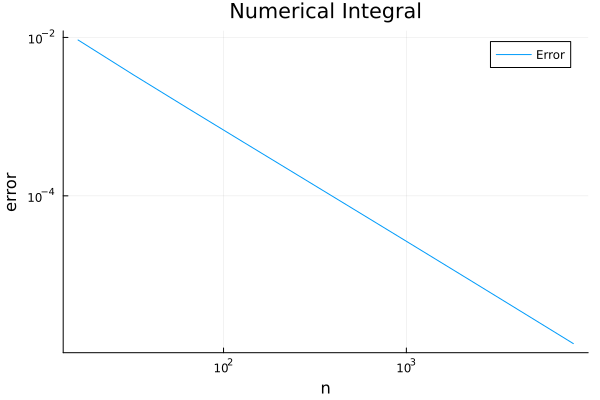

In [17]:
plot(ns, errs, yaxis=:log, xaxis=:log, title="Numerical Integral", xlabel="n", ylabel="error", label="Error")

## Q 5.7.6

Adaptive integration can have subtle drawbacks. This exercise is based on the error function, a smooth function defined as
$$\text{erf}(x)  = \frac{2}{\sqrt{\pi}}\int_0^x e^{-t^2}\ dt.$$
 
(a) Define a function $g$ that approximates erf by applying Function 5.6.4 with $n=300$. Make a plot of the error $g(x)-\text{erf}(x)$ at 500 points in the interval $[0,3]$.

(b) Define another approximation $h$ that applies Function 5.7.2 with error tolerance $10^{-7}$. Plot the error in $h$ as in part (a). Why does it look so different from the previous case?

(c) (Optional) Suppose you wished to find $x$ such that $\text{erf}(x) =0.5$ by using rootfinding on one of your two approximations. Why is the version from part (a) preferable?
 

In [18]:
# The reference implementation of erf
erf(0.0), erf(1.0), erf(2.0)

(0.0, 0.8427007929497149, 0.9953222650189527)

In [19]:
# 5.6.4 
"""
    trapezoid(f,a,b,n)

Apply the trapezoid integration formula for integrand `f` over
interval [`a`,`b`], broken up into `n` equal pieces. Returns
the estimate, a vector of nodes, and a vector of integrand values at the
nodes.
"""
function trapezoid(f,a,b,n)
    h = (b-a)/n
    t = range(a,b,length=n+1)
    y = f.(t)
    T = h * ( sum(y[2:n]) + 0.5*(y[1] + y[n+1]) )
    return T,t,y
end

# 5.7.2
"""
    intadapt(f,a,b,tol)

Adaptively integrate `f` over [`a`,`b`] to within target error 
tolerance `tol`. Returns the estimate and a vector of evaluation 
nodes.
"""
function intadapt(f,a,b,tol,fa=f(a),fb=f(b),m=(a+b)/2,fm=f(m))
    # Use error estimation and recursive bisection.
    # These are the two new nodes and their f-values.
    xl = (a+m)/2;  fl = f(xl);
    xr = (m+b)/2;  fr = f(xr);
    
    # Compute the trapezoid values iteratively.
    h = (b-a)
    T = [0.,0.,0.]
    T[1] = h*(fa+fb)/2
    T[2] = T[1]/2 + (h/2)*fm
    T[3] = T[2]/2 + (h/4)*(fl+fr)
    
    S = (4T[2:3]-T[1:2]) / 3      # Simpson values
    E = (S[2]-S[1]) / 15           # error estimate
    
    if abs(E) < tol*(1+abs(S[2]))  # acceptable error?
        Q = S[2]                   # yes--done
        nodes = [a,xl,m,xr,b]      # all nodes at this level
    else
        # Error is too large--bisect and recurse.
        QL,tL = intadapt(f,a,m,tol,fa,fm,xl,fl)
        QR,tR = intadapt(f,m,b,tol,fm,fb,xr,fr)
        Q = QL + QR
        nodes = [tL;tR[2:end]]   # merge the nodes w/o duplicate
    end
    return Q,nodes
end

intadapt

**(1)**

In [20]:
function g(x)
    n = 300
    in_f = t -> exp(-t ^ 2)
    T, ts, ys = trapezoid(in_f, 0, x, n)
    return T * 2 / sqrt(pi)
end

g (generic function with 1 method)

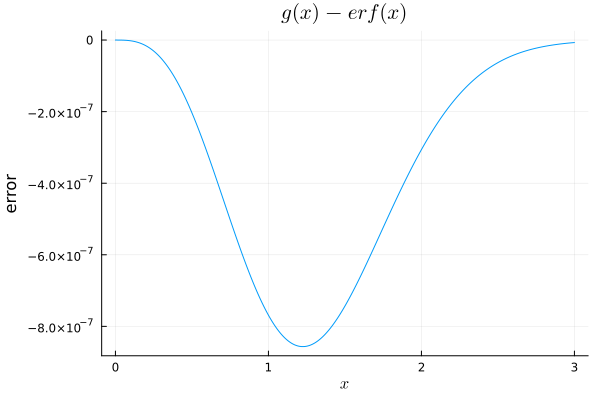

In [21]:
sps = LinRange(0, 3, 500)
err = x -> g(x) - erf(x)

plot(sps, err.(sps), label=nothing, xlabel=L"x", ylabel="error", title=L"g(x)-erf(x)")

**(2)**

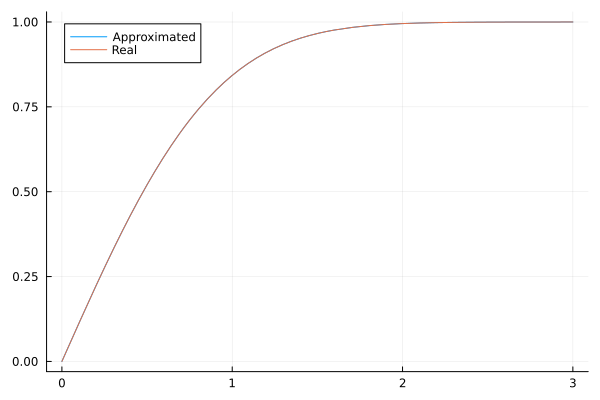

In [22]:
#pyplot()
plot(x -> intadapt(t -> 2 * exp(-t ^ 2) / sqrt(pi), 0, x, 1e-7)[1], 0, 3, label="Approximated")
plot!(erf, 0, 3, label="Real")

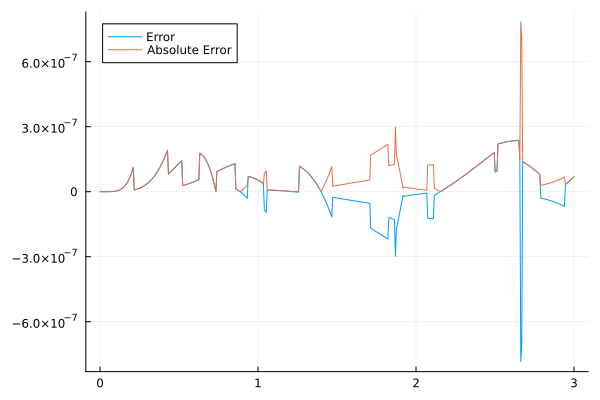

In [23]:
err = x -> intadapt(t -> 2 * exp(-t ^ 2) / sqrt(pi), 0, x, 1e-7)[1] - erf(x)
abs_err = x -> abs(err(x))
plot(sps, err.(sps), label="Error")
plot!(sps, abs_err.(sps), label="Absolute Error")

It differs a lot from the previous plot because at each calculation, we calculated the least number of knots to keep the tolerance within a specific range, hence the error function seems uniform. But in the previous plot, we used fixed number of knots, at some $x$, it may produce approximations much precious than the required tolerance while at some other $x$, it may produce much rough approximations. The error is not steady. 

## Q 6.2.4

Consider the problem $u'(t) = ku$, $u(0)=1$ for constant $k$ and $t>0$.

(a) Find an explicit formula in terms of $h$, $k$, and $i$ for the Euler solution $u_i$ at $t=ih$.

(b) Find values of $k$ and $h$ such that $|u_i|\to\infty$ as $i\to\infty$ while the exact solution $u(t)$ is bounded as $t\to\infty$.

(c) (added to the text question) Create a numerical demonstration of this fact.

**Answer:**

**(1)** $u_{i+1}=u_i+u'(t_i)h=(1+hk)u_i$

**(2)(3)** The analytical solution to the given ODE is $u(t)=\exp(kt)$, hence to meet the given demands, we should have

$$|u_{n+1}|=|(1+hk)|^n|u_0|=|(1+hk)|^n\to \infty \text{  as  } n\to\infty,\text{and  }hk < 0$$

Therefore $hk<-2$. For example, we can take $h=0.1,k=-20$.

In fact, when $hk<-2$, we have $1+hk < -1$, thus when adopting Euler's approach with such $h,k$, the intermediate values $u_i$ will jump between positive and negative values, the schema won't work.

## Q 6.5.1

Using Function 6.5.2 with an error tolerance of $10^{-8}$, solve $y''+ (1+y')^3y=0$ over $0\leq t \leq 4\pi$ with initial conditions $y(0)=0.1, y'(0)=0.0$. Plot $y$  and $y'$
 as functions of $t$ and separately plot the time step size as a function of $t$.


In [2]:
# function 6.5.2
"""
    rk23(ivp,tol)

Apply an adaptive embedded RK formula pair to solve given IVP with
estimated error `tol`. Returns a vector of times and a vector of
solution values.
"""
function rk23(ivp,tol)
    # Initialize for the first time step.
    a,b = ivp.tspan
    t = [a]
    u = [float(ivp.u0)];   i = 1;
    h = 0.5*tol^(1/3)
    s₁ = ivp.f(ivp.u0,ivp.p,a)

    # Time stepping.
    k = 0
    while t[i] < b && k < 1000000
        k += 1
        # Detect underflow of the step size.
        if t[i]+h == t[i]
            @warn "Stepsize too small near t=$(t[i])"
            break  # quit time stepping loop
        end

        # New RK stages.
        s₂ = ivp.f( u[i]+(h/2)*s₁,   ivp.p, t[i]+h/2   )
        s₃ = ivp.f( u[i]+(3h/4)*s₂, ivp.p, t[i]+3h/4 )
        unew2 = u[i] + h*(2s₁  + 3s₂ + 4s₃)/9   # 2rd order solution
        s₄ = ivp.f( unew2, ivp.p, t[i]+h )
        err = h*(-5s₁/72 + s₂/12 + s₃/9 - s₄/8)  # 2nd/3rd difference
        E = norm(err,Inf)                         # error estimate
        maxerr = tol*(1 + norm(u[i],Inf))     # relative/absolute blend

        # Accept the proposed step?
        if E < maxerr     # yes
            push!(t,t[i]+h)
            push!(u,unew2)
            i += 1
            s₁ = s₄       # use FSAL property
        end

        # Adjust step size.
        q = 0.8*(maxerr/E)^(1/3)   # conservative optimal step factor
        q = min(q,4)               # limit stepsize growth
        h = min(q*h,b-t[i])        # don't step past the end
    end
    return t,u
end

rk23

In [25]:
f = (u,p,t) -> [u[2], -(1+u[2])^3*u[1]]
ivp = ODEProblem(f,[0.1, 0],(0.,4*pi))
t,u = rk23(ivp,1e-8);

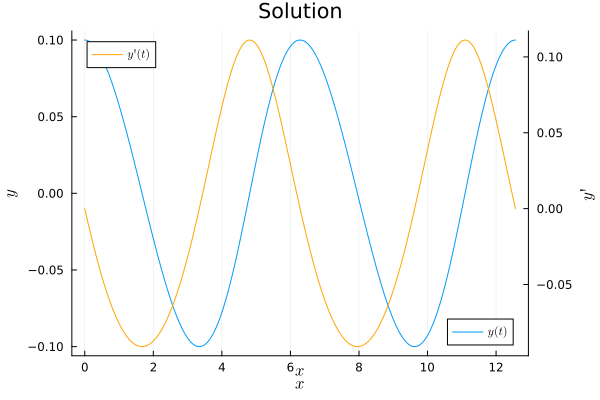

In [26]:
ys = zeros(length(u), 2)
for i = 1:length(u)
    ys[i, 1] = u[i][1]
    ys[i, 2] = u[i][2]
end

plot(t, ys[:, 1], label=L"y(t)", xlabel=L"x", ylabel=L"y", legend=:bottomright)
plot!(twinx(), t, ys[:, 2], label=L"y'(t)", xlabel=L"x", ylabel=L"y'", color=:orange, title="Solution")

## Q 6.5.4

The FitzHugh–Nagumo equations (exercise 6.3.6) are a simple model of the repeated firing of a neuron. They are given by

$v_1' = -v_1(v_1-1)(v_1-\alpha)-v_2+I$, $v_2' = \epsilon(v_1 - \gamma v_2)$

Use $\alpha = 0.1$, $\epsilon = 0.008$, $\gamma = 1$, $I = 0.05740$, $v_1(0)= 0.5$, $v_2(0) = 0.1$. 

Solve the system using rk23 for $0\leq t \leq 600$ and plot the solutions with error tolerances $10^{-2}$, $10^{-3}$, and $10^{-4}$.

Also solve the system using the Tsit5 solver and plot the solution.


In [3]:
α = 0.1
ε = 0.08
γ = 1
I = 0.05740
v10 = 0.5
v20 = 0.1

f654(u, p, t) = [-u[1]*(u[1]-1)*(u[1]-α)-u[2]+I, ε*(u[1]-γ*u[2])]

f654 (generic function with 1 method)

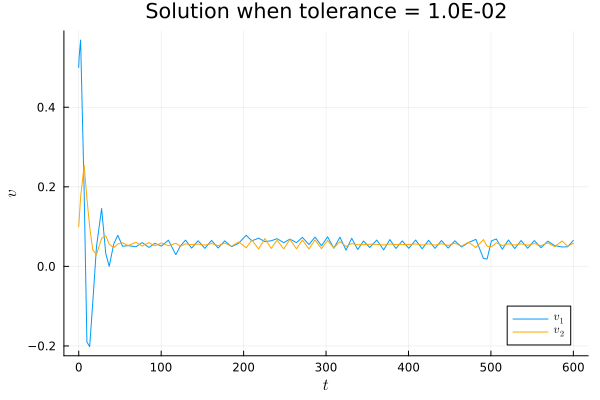

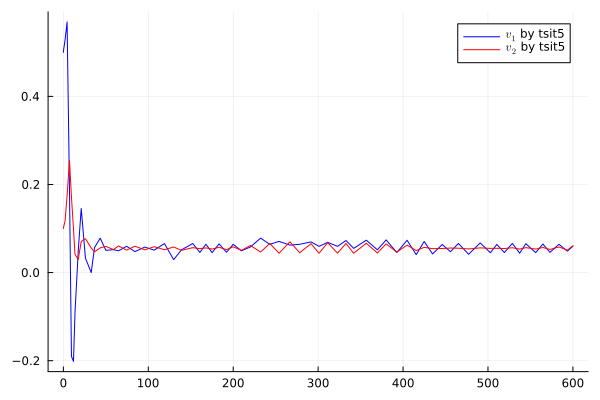

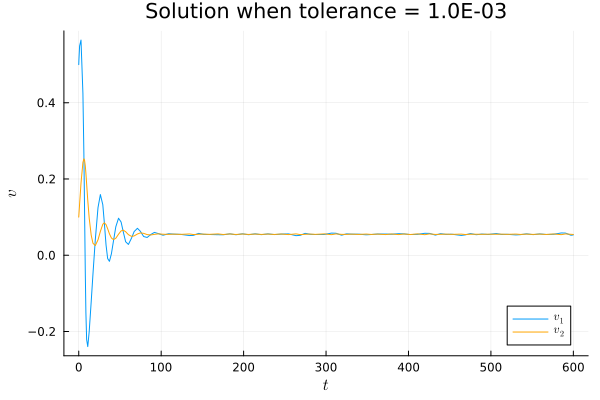

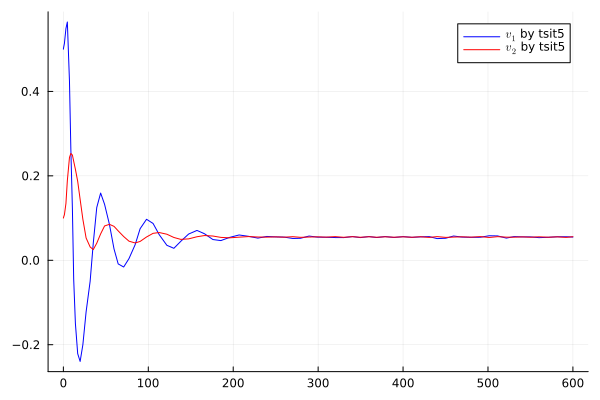

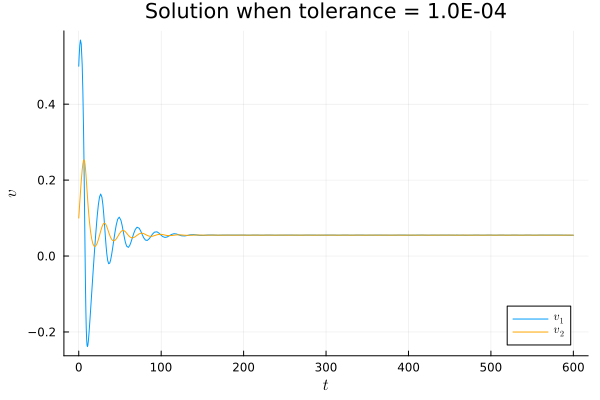

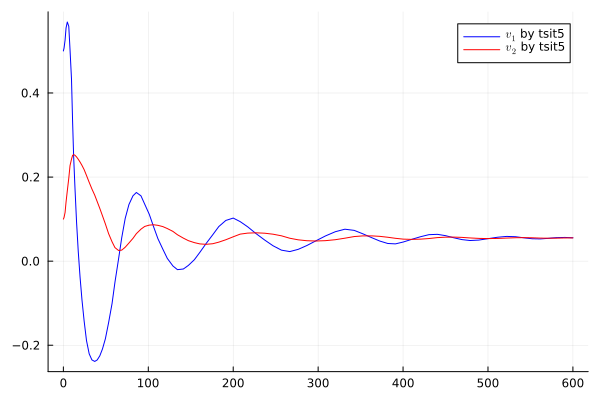

In [8]:
for tol = [1e-2, 1e-3, 1e-4]
    ivp = ODEProblem(f654,[v10, v20],(0.,600.))
    t,u = rk23(ivp, tol)
    
    ys = zeros(length(u), 2)
    for i = 1:length(u)
        ys[i, 1] = u[i][1]
        ys[i, 2] = u[i][2]
    end

    plot(t, ys[:, 1], label=L"v_1", xlabel=L"t", ylabel=L"v", legend=:bottomright)
    display(plot!(t, ys[:, 2], label=L"v_2", color=:orange, title="Solution when tolerance = "*@sprintf("%.1E",tol)))
    
    sol = solve(ivp,Tsit5(),reltol=tol,abstol=tol)
    ys = zeros(length(sol.u), 2)
    for i = 1:length(sol.u)
        ys[i, 1] = u[i][1]
        ys[i, 2] = u[i][2]
    end
    
    plot(sol.t, ys[:, 1], color=:blue, label=(L"v_1") * " by tsit5")
    display(plot!(sol.t, ys[:, 2], color=:red, label=(L"v_2") * " by tsit5"))
end


## Q 6.7.1.h

Solve the system $x^2u'' + 5xu' + 4 u = 0$ on the interval $1 \leq x \leq e^2$ using initial conditions $u(1)= 1$, $u'(1)=-1$ using ab4. 
Plot the solution $u(x)$ and the error relative to the exact solution $\hat u(x) = x^{-2}(1+\ln x)$. 

In [4]:
"""
    rk4(ivp,n)

Apply the common Runge-Kutta 4th order method to solve the given 
IVP using `n` time steps. Returns a vector of times and a vector of
solution values.
"""
function rk4(ivp,n)
    # Time discretization.
    a,b = ivp.tspan
    h = (b-a)/n
    t = [ a + i*h for i in 0:n ]

    # Initialize output.
    u = fill(float(ivp.u0),n+1)

    # Time stepping.
    for i in 1:n
        k₁ = h*ivp.f( u[i],      ivp.p, t[i]     )
        k₂ = h*ivp.f( u[i]+k₁/2, ivp.p, t[i]+h/2 )
        k₃ = h*ivp.f( u[i]+k₂/2, ivp.p, t[i]+h/2 )
        k₄ = h*ivp.f( u[i]+k₃,   ivp.p, t[i]+h   )
        u[i+1] = u[i] + (k₁ + 2(k₂+k₃) + k₄)/6
    end
    return t,u
end

rk4

In [52]:
"""
    ab4(ivp,n)

Apply the Adams-Bashforth 4th order method to solve the given IVP
using `n` time steps. Returns a vector of times and a vector of
solution values.
"""
function ab4(ivp,n) 
    # Time discretization.
    a,b = ivp.tspan
    h = (b-a)/n
    t = [ a + i*h for i in 0:n ]

    # Constants in the AB4 method.
    k = 4;   σ = [55,-59,37,-9]/24;

    # Find starting values by RK4.
    u = [float(ivp.u0) for _ in 1:(n+1)]
    rkivp = ODEProblem(ivp.f,ivp.u0,(a,a+(k-1)*h),ivp.p)
    ts,us = rk4(rkivp,k-1)
    
    u[1:k, :] = us

    # Compute history of u' values, from newest to oldest.
    # for i in 1:k-1 
    #     @show i
    #     @show u[k-i]
    #     @show t[k-i]

    #     println("---")
    #     ivp.f(u[k-i],ivp.p,t[k-i])
    # end
    f = [ ivp.f(u[k-i],ivp.p,t[k-i]) for i in 1:k-1  ]

    # Time stepping.
    for i in k:n
        f = [ ivp.f(u[i],ivp.p,t[i]), f[1:k-1]... ]   # new value of du/dt
        u[i+1] = u[i] + h*sum(f[j]*σ[j] for j in 1:k)  # advance a step
    end
    return t,u
end

ab4

In [53]:
ef = x -> x^(-2) * (1+log(x))

fk = (u,p,t) -> [u[2], -5 * u[2] / t - 4 * u[1] / t ^ 2]
ivp = ODEProblem(fk,[1, -1],(1., exp(2.)))
t, u = ab4(ivp, 50);

i = 1
u[k - i] = [0.7786993396765872, -0.7351625312080576]
t[k - i] = 1.255562243957226
---
i = 2
u[k - i] = [0.8807657356615888, -0.8647808603463957]
t[k - i] = 1.1277811219786131
---
i = 3
u[k - i] = [1.0, -1.0]
t[k - i] = 1.0
---


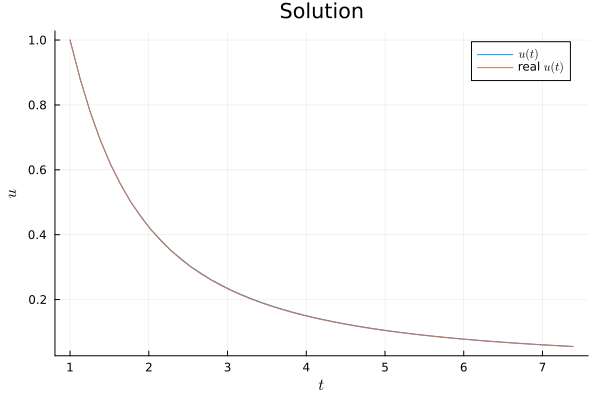

In [72]:
ys = zeros(length(u), 2)
for i = 1:length(u)
    ys[i, 1] = u[i][1]
    ys[i, 2] = u[i][2]
end

real_ys = ef.(t)
plot(t, ys[:, 1], label=L"u(t)", xlabel=L"t", ylabel=L"u", title="Solution")
plot!(t, real_ys, label="real "*L"u(t)")

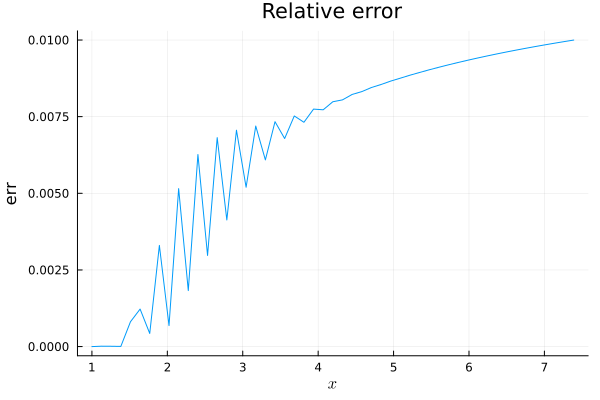

In [71]:
plot(t, abs.(ys[:, 1] - real_ys) ./ real_ys, xlabel=L"x", ylabel="err", label=nothing, title="Relative error", legend=:bottomright)